# Projekttitel

# Projektbeschreibung

## Analyse tödlicher Verkehrsunfälle in Deutschland

### 1. Projektübersicht
In diesem Projekt werden **tödliche Verkehrsunfälle in Deutschland** mithilfe von Daten aus dem **Unfallatlas 2025** analysiert. Ziel ist es, zeitliche, regionale und verkehrsbezogene Muster zu identifizieren und mögliche Zusammenhänge zwischen verschiedenen Unfallmerkmalen zu untersuchen.

Der Schwerpunkt liegt auf der explorativen Datenanalyse (Exploratory Data Analysis, EDA) und der Visualisierung der Ergebnisse mit Python.

---
## 2. Zielsetzung

Das Hauptziel des Projekts ist es, anhand der Unfallatlas-Daten zu untersuchen, **wann, wo und unter welchen Bedingungen tödliche Verkehrsunfälle besonders häufig auftreten**.

Dabei sollen insbesondere folgende Fragestellungen beantwortet werden:

- An welchen **Wochentagen** ereignen sich die meisten tödlichen Verkehrsunfälle?
- Gibt es Unterschiede zwischen den einzelnen **Monaten**?
- Zu welchen **Tageszeiten** treten besonders viele tödliche Unfälle auf?
- Wie häufig waren Fahrräder, Pkw, Fußgänger, Motorräder und Güterkraftfahrzeuge an Verkehrsunfällen beteiligt? 
- Wie häufig treten die verschiedenen Verkehrsteilnehmergruppen – Fußgänger, Radfahrer, Pkw, Güterkraftfahrzeuge (Gkfz), Krafträder (Krad) und sonstige Verkehrsmittel (e.g. Bus, Tram etc) – gemeinsam in Verkehrsunfällen auf?
- Gibt es **regionale Unterschiede** zwischen Bundesländern?
- Lassen sich **räumliche Unfallhäufungen bzw. Hotspots** erkennen?
- Wie verteilen sich tödliche Unfälle auf **Tageslicht und Verkehrsteilnehmergruppen**?
- Gibt es Zusammenhänge zwischen **Wochentag, Tageszeit**?


## 3. Datengrundlage

Als Datengrundlage wird der **Unfallatlas 2025** verwendet. Der Datensatz enthält Informationen zu Verkehrsunfällen mit Personenschaden in Deutschland.

Für die Analyse werden ausschließlich **Unfälle mit Getöteten** betrachtet.

Besonders relevante Variablen sind:

| Variable | Bedeutung |
|---|---|
| `UJAHR` | Unfalljahr |
| `UMONAT` | Unfallmonat |
| `USTUNDE` | Unfallstunde |
| `UWOCHENTAG` | Wochentag des Unfalls |
| `UKATEGORIE` | Unfallkategorie |
| `IstRad` | Fahrrad |
| `IstPKW` | PKW |
| `IstFuss` | Fußgänger |
| `IstKrad` | Motorrad |
| `IstGkfz` | Güterkraftfahrzeug |

### Daten Quelle: 

- [Unfallatlas](https://unfallatlas.statistikportal.de/)

  - [CSV format](https://www.opengeodata.nrw.de/produkte/transport_verkehr/unfallatlas/Unfallorte2025_EPSG25832_CSV.zip)

  - [Schema Beschreibung](https://www.opengeodata.nrw.de/produkte/transport_verkehr/unfallatlas/DSB_Unfallatlas.pdf)

- [JSON Geo](https://naturalearth.s3.amazonaws.com/10m_cultural/)

- [Bundesländer Deutschland](https://geodata.ucdavis.edu/gadm/gadm4.1/json/)

- [Destasis Bevölkerung](https://www.destatis.de/EN/Themes/Society-Environment/Population/Current-Population/Tables/population-by-laender-basis-2022.html)


# Teil 1: Data Vorbereiten und DeskriptivAnalyse

<a class="anchor" id="0.1"></a>
# Table of Contents 

1. [Daten Laden](#1)
2. [Daten Vorbereitung](#2)
3. [Deskriptivanalyse (Univariat)](#3)
   - 3.1 [Unfälle nach Wochentag](#31)
   - 3.2 [Unfälle nach Monat](#32)
   - 3.3 [Unfälle nach Tageszeit](#33)
   - 3.4 [Unfälle nach Verkehrsteilnehmer](#34)


# 1. Daten Laden  <a class="anchor" id="1"></a>


In [1]:
import pandas as pd

df=pd.read_csv(r'data\Unfallorte_2025_LR_BasisDLM.csv',sep=';')
df.info()

C:\Users\abdel\AppData\Local\Temp\ipykernel_28664\1827561073.py:3: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(r'data\Unfallorte_2025_LR_BasisDLM.csv',sep=';')


<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   UIDENTSTLAE         273007 non-null  object
 1   ULAND               273007 non-null  int64 
 2   UREGBEZ             273007 non-null  int64 
 3   UKREIS              273007 non-null  int64 
 4   UGEMEINDE           273007 non-null  int64 
 5   UJAHR               273007 non-null  int64 
 6   UMONAT              273007 non-null  int64 
 7   USTUNDE             273007 non-null  int64 
 8   UWOCHENTAG          273007 non-null  int64 
 9   UKATEGORIE          273007 non-null  int64 
 10  UART                273007 non-null  int64 
 11  UTYP1               273007 non-null  int64 
 12  ULICHTVERH          273007 non-null  int64 
 13  IstStrassenzustand  273007 non-null  int64 
 14  IstRad              273007 non-null  int64 
 15  IstPKW              273007 non-null  int64 
 16  IstFuss      

In [2]:
df.UART.value_counts()

UART
5    72677
0    50163
2    42448
8    21292
6    21104
4    18985
3    15275
1    15124
9    12947
7     2992
Name: count, dtype: int64

In [3]:
dft =df[df['UKATEGORIE']==1] # Tödliche Unfälle
dft.USTUNDE.value_counts(normalize=True)

USTUNDE
15    0.081954
17    0.081147
14    0.079935
16    0.075495
13    0.068631
11    0.062172
12    0.060153
10    0.051675
18    0.049657
9     0.044005
19    0.039564
7     0.037949
20    0.037545
8     0.034316
6     0.027856
22    0.026645
21    0.025838
23    0.023415
0     0.018975
1     0.016149
5     0.015745
3     0.014130
2     0.013726
4     0.013323
Name: proportion, dtype: float64

### Großes teil von Unfalls passieren nachmittag zwichen 13 und 17 Uhr  38 % in 5 Stunden

In [4]:
dft.describe(include=['str','object','category'])

,UIDENTSTLAE,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84
count,2477,2477,2477,2477,2477
unique,2477,2477,2477,2477,2477
top,01250105125013052025,"508989,123300000093877","6036980,500199999660254","9,138737056000025","54,480384718000039"
freq,1,1,1,1,1


In [5]:
df.describe()

,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,UART,UTYP1,ULICHTVERH,IstStrassenzustand,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,PLST
count,273007.000000,273007.000000,273007.000000,273007.000000,273007.0,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000,273007.000000
mean,7.380708,2.813027,42.113495,63.284784,2025.0,6.641009,13.439589,4.115433,2.833763,3.734692,3.862579,0.421495,0.240891,0.327907,0.723784,0.088045,0.134421,0.039776,0.144949,1.027073
std,3.639742,2.479057,26.117377,107.287581,0.0,3.180641,4.780902,1.876195,0.395916,2.674599,2.193928,0.783697,0.471796,0.469452,0.447126,0.283361,0.341105,0.195432,0.352050,0.162295
min,1.000000,0.000000,1.000000,0.000000,2025.0,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,5.000000,1.000000,15.000000,0.000000,2025.0,4.000000,10.000000,3.000000,3.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,7.000000,3.000000,41.000000,17.000000,2025.0,7.000000,14.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,9.000000,4.000000,64.000000,90.000000,2025.0,9.000000,17.000000,6.000000,3.000000,5.000000,6.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,16.000000,9.000000,91.000000,718.000000,2025.0,12.000000,23.000000,7.000000,3.000000,9.000000,7.000000,2.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000


In [6]:
dft.corr(numeric_only=True)

,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,UART,UTYP1,ULICHTVERH,IstStrassenzustand,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,PLST
ULAND,1.000000,-0.208261,0.166134,0.405513,NaN,0.005904,0.015491,-0.002696,NaN,0.078116,-0.016557,-0.025327,-0.005818,-0.062623,-0.030943,0.008680,-0.000299,0.023450,0.021273,-0.017244
UREGBEZ,-0.208261,1.000000,-0.114732,-0.074269,NaN,-0.012256,-0.007840,-0.040211,NaN,-0.000741,-0.035665,0.022405,-0.007673,0.011721,-0.003610,-0.016015,0.014826,-0.003444,-0.042222,-0.013120
UKREIS,0.166134,-0.114732,1.000000,0.235199,NaN,0.007057,0.017647,-0.006264,NaN,0.053234,0.013774,-0.022341,0.045177,-0.035913,0.054501,-0.133022,0.003719,0.024443,-0.068669,-0.032680
UGEMEINDE,0.405513,-0.074269,0.235199,1.000000,NaN,-0.023642,-0.006304,0.030096,NaN,0.055107,0.009143,-0.031727,-0.011112,-0.023690,0.041265,-0.075328,0.018801,0.006760,-0.016267,-0.026861
UJAHR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UMONAT,0.005904,-0.012256,0.007057,-0.023642,NaN,1.000000,0.015821,-0.020593,NaN,-0.015557,0.007475,0.055644,0.063123,-0.030554,0.009385,0.008037,-0.021942,0.006896,0.009395,0.000753
USTUNDE,0.015491,-0.007840,0.017647,-0.006304,NaN,0.015821,1.000000,0.052522,NaN,-0.031642,-0.020903,-0.016174,-0.086131,0.044031,-0.050664,0.025987,0.111146,-0.119336,-0.012226,0.025596
UWOCHENTAG,-0.002696,-0.040211,-0.006264,0.030096,NaN,-0.020593,0.052522,1.000000,NaN,-0.023880,-0.026205,0.004680,-0.032600,0.015198,-0.029991,0.035285,0.029129,-0.043100,0.033860,0.027042
UKATEGORIE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UART,0.078116,-0.000741,0.053234,0.055107,NaN,-0.015557,-0.031642,-0.023880,NaN,1.000000,-0.381550,0.116513,0.058103,-0.303576,0.076421,0.094973,0.048530,-0.185396,-0.122255,-0.086219


In [7]:
# UKATEGORIE Road traffic accidents involving personal injury
# 1 = Accident with persons killed
# 2 = Accident with seriously injured
# 3 = Accident with slightly injured
df.UKATEGORIE.value_counts()

UKATEGORIE
3    230100
2     40430
1      2477
Name: count, dtype: int64

In [8]:
#dft 1 = Accident with persons killed
dft =df[df['UKATEGORIE']==1]
print(len(dft))
dfOrg=df.copy()

2477


# 2.Data Vorbereiten  <a class="anchor" id="2"></a>

[Table of Contents](#0.1)
## 2.1 Map codes in the dataset to text values

In [9]:
#Data Vorbereiten

df_plot =dfOrg[dfOrg['UKATEGORIE']==1]

# Mapping der Lichtverhältnisse
licht = {
    0: "Tageslicht",
    1: "Dämmerung",
    2: "Dunkelheit"
}

# Bundeslander names 
uland_names = {
    1:  "Schleswig-Holstein",
    2:  "Hamburg",
    3:  "Niedersachsen",
    4:  "Bremen",
    5:  "Nordrhein-Westfalen",
    6:  "Hessen",
    7:  "Rheinland-Pfalz",
    8:  "Baden-Württemberg",
    9:  "Bayern",
    10: "Saarland",
    11: "Berlin",
    12: "Brandenburg",
    13: "Mecklenburg-Vorpommern",
    14: "Sachsen",
    15: "Sachsen-Anhalt",
    16: "Thüringen"
}

# Mapping der Unfallkategorien
kategorien = {
    1: "Getötete",
    2: "Schwerverletzte",
    3: "Leichtverletzte"
}

# Zahlen → deutsche Wochentage
tage = {
    1: "Sonntag",
    2: "Montag",
    3: "Dienstag",
    4: "Mittwoch",
    5: "Donnerstag",
    6: "Freitag",
    7: "Samstag"    
}

# Monat Nr ->
monate = {
    1: "Januar",
    2: "Februar",
    3: "März",
    4: "April",
    5: "Mai",
    6: "Juni",
    7: "Juli",
    8: "August",
    9: "September",
    10: "Oktober",
    11: "November",
    12: "Dezember"
}

df_plot["Monat_Name"] = df_plot["UMONAT"].map(monate)
df_plot["Wochentag"] = df_plot["UWOCHENTAG"].map(tage)
# Daten kopieren und Kategorien übersetzen

df_plot["Lichtverhältnisse"] = df_plot["ULICHTVERH"].map(licht)
df_plot["Unfallkategorie"] = df_plot["UKATEGORIE"].map(kategorien)
df_plot["Bundesland"] = df_plot["ULAND"].map(uland_names)

df_plot.to_pickle(r'Data\ToedlicheUnfaelle_DE_J2025.pkl')


## 2.2 DOWNLOAD GERMANY MAP ONCE AND SAVE LOCALLY

In [10]:
# ============================================================
# DOWNLOAD GERMANY MAP ONCE AND SAVE LOCALLY
# ============================================================
from pathlib import Path
import geopandas as gpd

file_path = Path("data/germany.geojson")

if not file_path.exists():
    # Natural Earth countries dataset
    url = (
        "https://naturalearth.s3.amazonaws.com/10m_cultural/"
        "ne_10m_admin_0_countries.zip"
    )

    world = gpd.read_file(url)
    germany = world[world["ADMIN"] == "Germany"].copy()

    germany.to_file(file_path, driver="GeoJSON")

    print("Germany GeoJSON downloaded and saved.")
else:
    print("Germany GeoJSON already exists. Download skipped.")


Germany GeoJSON already exists. Download skipped.


In [11]:
# ============================================================
# DOWNLOAD: Bundesländer Deutschland
# Save locally as bundeslaender.geojson
# ============================================================

import geopandas as gpd

# ------------------------------------------------------------
# 1. Natural Earth administrative boundaries
# ------------------------------------------------------------

file_path = Path("data/bundeslaender.geojson")

if not file_path.exists():
    url = (
        "https://geodata.ucdavis.edu/gadm/gadm4.1/json/"
        "gadm41_DEU_1.json"
    )
    
    # ------------------------------------------------------------
    # 2. Download Bundesländer
    # ------------------------------------------------------------
    
    bundeslaender = gpd.read_file(url)
    
    # ------------------------------------------------------------
    # 3. Check the data
    # ------------------------------------------------------------
    
    print("Anzahl Bundesländer:", len(bundeslaender))
    print(bundeslaender.columns.tolist())
    
    # ------------------------------------------------------------
    # 4. Save locally as GeoJSON
    # ------------------------------------------------------------
    
    bundeslaender.to_file(
        "data/bundeslaender.geojson",
        driver="GeoJSON"
    )
    print("\nGespeichert als: bundeslaender.geojson")
else:
    print(" Bundesländer Deutschland GeoJSON already exists. Download skipped.")

 Bundesländer Deutschland GeoJSON already exists. Download skipped.


In [12]:
#Source :https://www.destatis.de/EN/Themes/Society-Environment/Population/Current-Population/Tables/population-by-laender-basis-2022.html
# Bevoelkerungsdichte für Deutschland
bundesland_data = {
    1:  {"Bundesland": "Schleswig-Holstein",      "Bevoelkerung": 2958519,  "Bevoelkerungsdichte": 187},
    2:  {"Bundesland": "Hamburg",                 "Bevoelkerung": 1869473,  "Bevoelkerungsdichte": 2452},
    3:  {"Bundesland": "Niedersachsen",           "Bevoelkerung": 8000826,  "Bevoelkerungsdichte": 168},
    4:  {"Bundesland": "Bremen",                  "Bevoelkerung": 706915,   "Bevoelkerungsdichte": 1675},
    5:  {"Bundesland": "Nordrhein-Westfalen",     "Bevoelkerung": 17986214, "Bevoelkerungsdichte": 528},
    6:  {"Bundesland": "Hessen",                  "Bevoelkerung": 6278594,  "Bevoelkerungsdichte": 297},
    7:  {"Bundesland": "Rheinland-Pfalz",         "Bevoelkerung": 4123022,  "Bevoelkerungsdichte": 208},
    8:  {"Bundesland": "Baden-Württemberg",       "Bevoelkerung": 11238761, "Bevoelkerungsdichte": 314},
    9:  {"Bundesland": "Bayern",                  "Bevoelkerung": 13245503, "Bevoelkerungsdichte": 187},
    10: {"Bundesland": "Saarland",                "Bevoelkerung": 1007342,  "Bevoelkerungsdichte": 394},
    11: {"Bundesland": "Berlin",                  "Bevoelkerung": 3700577,  "Bevoelkerungsdichte": 4110},
    12: {"Bundesland": "Brandenburg",             "Bevoelkerung": 2551889,  "Bevoelkerungsdichte": 86},
    13: {"Bundesland": "Mecklenburg-Vorpommern",  "Bevoelkerung": 1573685,  "Bevoelkerungsdichte": 68},
    14: {"Bundesland": "Sachsen",                 "Bevoelkerung": 4026599,  "Bevoelkerungsdichte": 220},
    15: {"Bundesland": "Sachsen-Anhalt",          "Bevoelkerung": 2120252,  "Bevoelkerungsdichte": 104},
    16: {"Bundesland": "Thüringen",               "Bevoelkerung": 2078946,  "Bevoelkerungsdichte": 131},
}

#import pandas as pd

bundesland_df = (
    pd.DataFrame.from_dict(
        bundesland_data,
        orient="index"
    )
    .reset_index()
    .rename(columns={"index": "ULAND"})
)

bundesland_df.to_pickle(r'Data\Bundesland_pop_J2025.pkl')

# 3 Deskriptivanalyse (Univariat) <a class="anchor" id="3"></a>
[Table of Contents](#0.1)

## 3.1 Q1 An welchen Wochentagen passieren die meisten tödlichen Verkehrsunfälle?  <a class="anchor" id="31"></a>

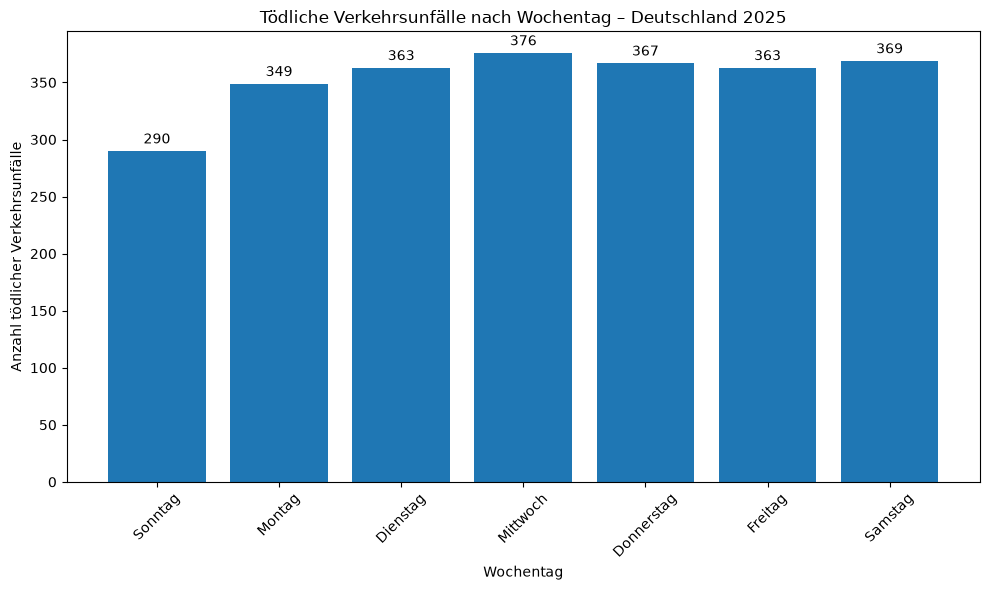

In [13]:
import matplotlib.pyplot as plt

df=df_plot.copy()

# Anzahl der Unfälle pro Wochentag
weekday_counts = df["Wochentag"].value_counts()

# richtige Reihenfolge
weekday_counts = weekday_counts.reindex(tage.values())

# Balkendiagramm
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(weekday_counts.index, weekday_counts.values)

# Werte auf den Balken
ax.bar_label(bars, padding=3)

ax.set_title("Tödliche Verkehrsunfälle nach Wochentag – Deutschland 2025")
ax.set_xlabel("Wochentag")
ax.set_ylabel("Anzahl tödlicher Verkehrsunfälle")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Result Analysis: Sonntags passiert weniger tödlich Verkehrsunfälle, Donnerstag ist slightly mehr als die Reste

## 3.2 An welchen Monaten passieren die meisten tödlichen Verkehrsunfälle?  <a class="anchor" id="32"></a>

[Table of Contents](#0.1)

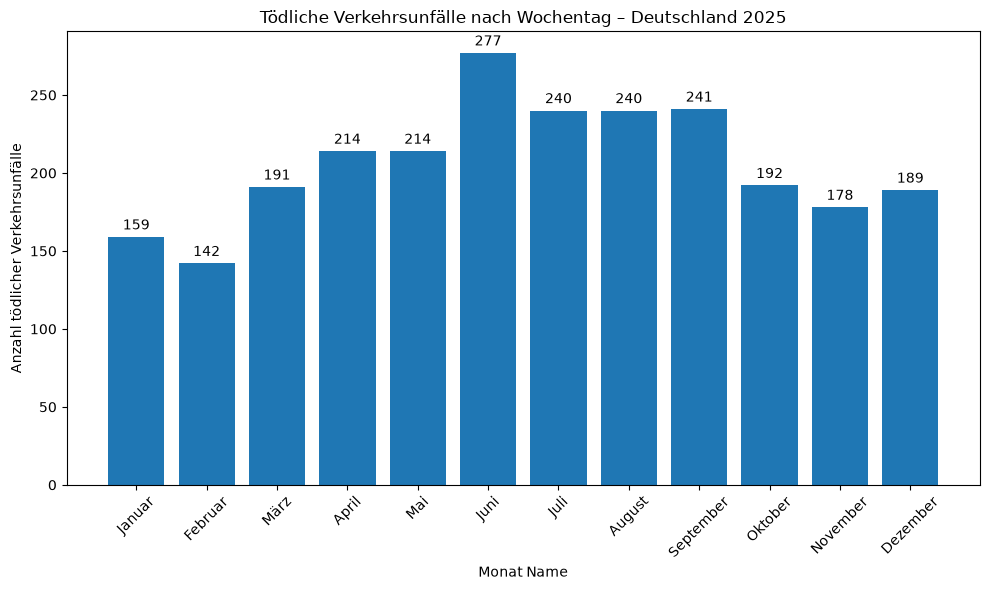

In [14]:
import matplotlib.pyplot as plt

df=df_plot.copy()

# Anzahl der Unfälle pro Wochentag
months_counts = df["Monat_Name"].value_counts()

# richtige Reihenfolge
months_counts = months_counts.reindex(monate.values())

# Balkendiagramm
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(months_counts.index, months_counts.values)

# Werte auf den Balken
ax.bar_label(bars, padding=3)

ax.set_title("Tödliche Verkehrsunfälle nach Wochentag – Deutschland 2025")
ax.set_xlabel("Monat Name")
ax.set_ylabel("Anzahl tödlicher Verkehrsunfälle")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Februar und Januar haben weniger tödliche Unfälle. Juni hat deutlich mehr tödlich Unfälle.

## 3.3 Q2 An welchen Stunden passieren die meisten tödlichen Verkehrsunfälle?  <a class="anchor" id="33"></a>

[Table of Contents](#0.1)

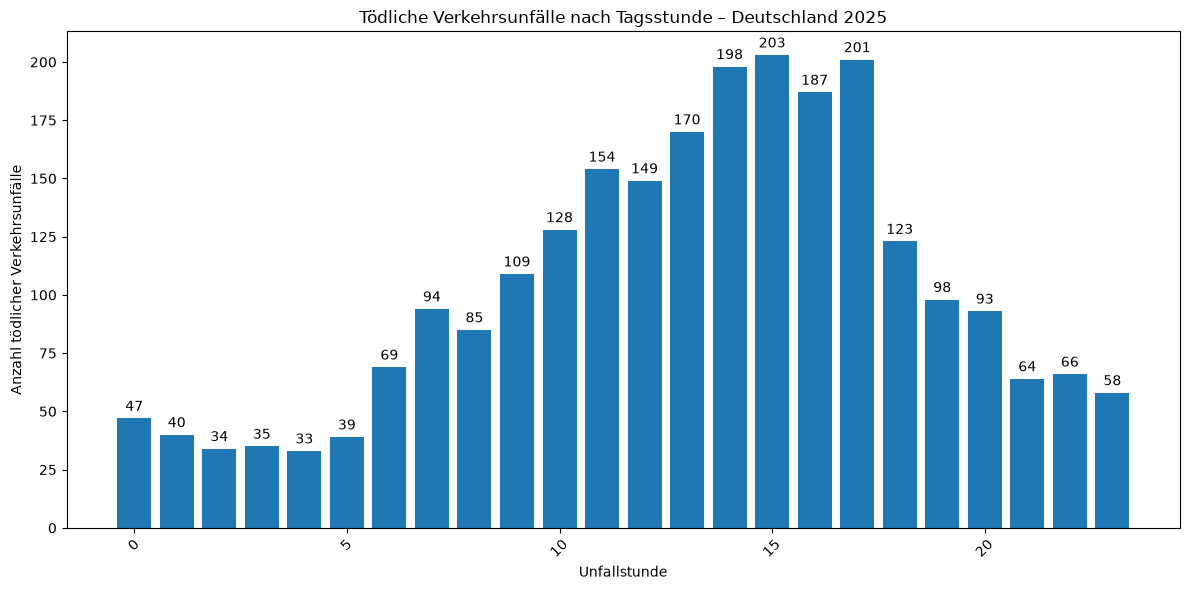

In [15]:
import matplotlib.pyplot as plt

df=df_plot.copy()

# Anzahl der Unfälle pro Wochentag
hrs_counts = df["USTUNDE"].value_counts()

# Balkendiagramm
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(hrs_counts.index, hrs_counts.values)

# Werte auf den Balken
ax.bar_label(bars, padding=3)

ax.set_title("Tödliche Verkehrsunfälle nach Tagsstunde – Deutschland 2025")
ax.set_xlabel("Unfallstunde")
ax.set_ylabel("Anzahl tödlicher Verkehrsunfälle")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

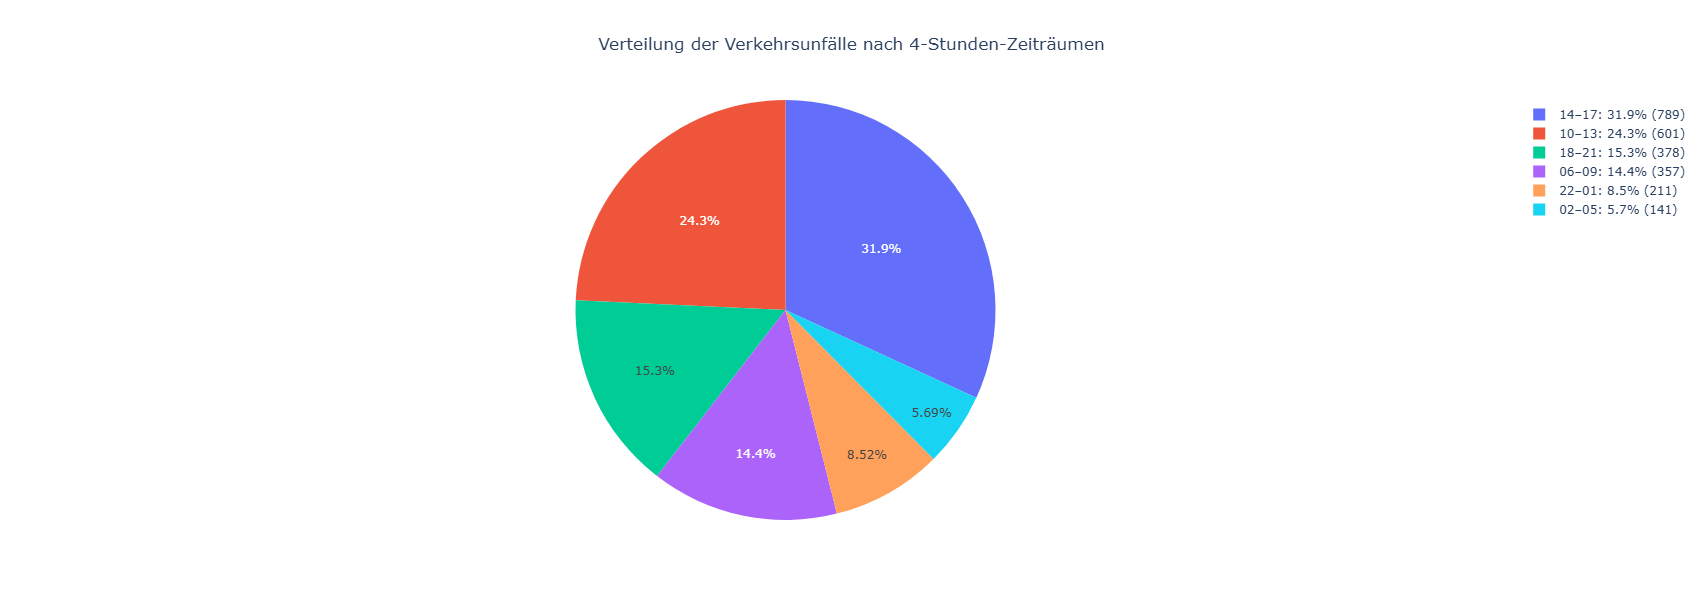

In [16]:
import pandas as pd
import plotly.express as px

# Define the 4-hour periods
def zeitperiode(stunde):
    if 2 <= stunde <= 5:
        return "02–05"
    elif 6 <= stunde <= 9:
        return "06–09"
    elif 10 <= stunde <= 13:
        return "10–13"
    elif 14 <= stunde <= 17:
        return "14–17"
    elif 18 <= stunde <= 21:
        return "18–21"
    else:  # 22, 23, 0, 1
        return "22–01"

df["Zeitperiode"] = df["USTUNDE"].apply(zeitperiode)

# Count accidents per period
counts = df["Zeitperiode"].value_counts()

# Keep chronological order
order = ["02–05", "06–09", "10–13", "14–17", "18–21", "22–01"]
counts = counts.reindex(order)

# Calculate percentages
pct = counts / counts.sum() * 100

# Create labels containing percentage and number
labels = [
    f"{period}: {pct[period]:.1f}% ({counts[period]:,})"
    for period in order
]

# Pie chart
fig = px.pie(
    values=counts.values,
    names=labels,
    title="Verteilung der Verkehrsunfälle nach 4-Stunden-Zeiträumen",
    hole=0
)

fig.update_traces(
    textinfo="percent",
    hovertemplate="<b>%{label}</b><br>Anzahl: %{value:,}<br>Anteil: %{percent}<extra></extra>"
)

fig.update_layout(
    title_x=0.5,
    width=800,
    height=600
)

fig.show()

### Stunden 14 bis 17 haben die meisten tödliche Unfälle (insges. ~32%) dagegen Stunden 2 bis 5 haben die wenigsten tödliche Unfällen (insgesamt ~6%).

## 3.4 Q4 Wie häufig waren Fahrräder, Pkw, Fußgänger, Motorräder und Güterkraftfahrzeuge an Verkehrsunfällen beteiligt?  <a class="anchor" id="34"></a>

[Table of Contents](#0.1)

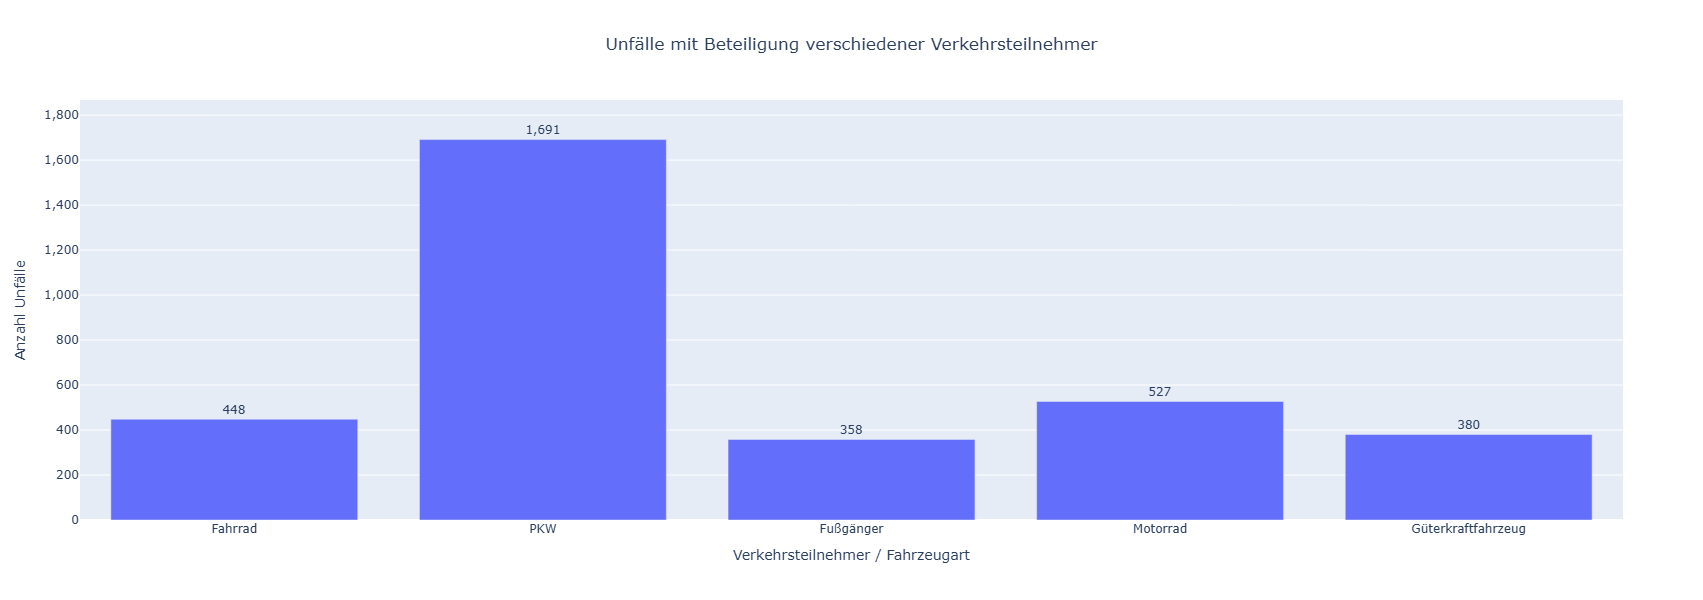

In [17]:
# count plot 
import pandas as pd
import plotly.express as px

# ---------------------------------------------------
# Variables and German labels
# ---------------------------------------------------

vars_unfaelle = {
    "IstRad": "Fahrrad",
    "IstPKW": "PKW",
    "IstFuss": "Fußgänger",
    "IstKrad": "Motorrad",
    "IstGkfz": "Güterkraftfahrzeug"
}


# ---------------------------------------------------
# Count accidents involving each category
# ---------------------------------------------------

df_counts = pd.DataFrame({
    "Kategorie": [
        "Fahrrad",
        "PKW",
        "Fußgänger",
        "Motorrad",
        "Güterkraftfahrzeug"
    ],
    "Anzahl Unfälle": [
        df["IstRad"].sum(),
        df["IstPKW"].sum(),
        df["IstFuss"].sum(),
        df["IstKrad"].sum(),
        df["IstGkfz"].sum()
    ]
})


# ---------------------------------------------------
# Create count plot
# ---------------------------------------------------

fig = px.bar(
    df_counts,
    x="Kategorie",
    y="Anzahl Unfälle",
    text="Anzahl Unfälle",
    title="Unfälle mit Beteiligung verschiedener Verkehrsteilnehmer",
    labels={
        "Kategorie": "Verkehrsteilnehmer / Fahrzeugart",
        "Anzahl Unfälle": "Anzahl Unfälle"
    },
    width=900,
    height=600
)


# ---------------------------------------------------
# Display values above bars
# ---------------------------------------------------

fig.update_traces(
    texttemplate="%{text:,}",
    textposition="outside"
)


# ---------------------------------------------------
# Layout
# ---------------------------------------------------

fig.update_layout(
    title_x=0.5,
    yaxis=dict(
        tickformat=","
    )
)

fig.show()

### Pkw die mit Abstand häufigste Beteiligung an den untersuchten Verkehrsunfällen aufweisen. Die Kategorien sind dabei nicht gegenseitig ausschließend, da an einem Unfall mehrere Verkehrsteilnehmer- oder Fahrzeugarten beteiligt sein können.